In [22]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np


# WMV in CST
cst = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_WM', 'summary_MNISymC_CST_WM_mod.tsv'), sep = '\t')
cst = cst[cst.isPatient==1] # just patients

cst['hemisphere'] = cst.regionname.str[-1]

cst_wide = cst.pivot(index = ['subj_id', 'Week', 'region_bilat'], columns = 'hemisphere', values = 'mean')
cst_wide['right_norm'] = cst_wide['R']/cst_wide['L']
cst_wide = cst_wide.reset_index()
cst = cst_wide.melt(
    id_vars = ['subj_id', 'Week', 'region_bilat'],
    value_vars = ['R', 'L', 'right_norm'],
    var_name = 'metric_cst', value_name = 'mean_cst'
)
cst = cst[cst.metric_cst == 'right_norm']
cst = cst.drop(columns = 'metric_cst')
cst = cst.rename(columns = {'mean_cst': 'right_norm'})

# GMV in pons
pons = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_pons_GM_mod.tsv'), sep = '\t')
pons = pons[pons.isPatient==1] # just patients

pons['hemisphere'] = pons.regionname.str[-1]

pons_wide = pons.pivot(index = ['subj_id', 'Week', 'region_bilat'], columns = 'hemisphere', values = 'mean')
pons_wide['right_norm'] = pons_wide['R']/pons_wide['L']
pons_wide = pons_wide.reset_index()
pons = pons_wide.melt(
    id_vars = ['subj_id', 'Week', 'region_bilat'],
    value_vars = ['R', 'L', 'right_norm'],
    var_name = 'metric_pons', value_name = 'mean_pons'
)
pons = pons[pons.metric_pons == 'right_norm']
pons = pons.drop(columns = 'metric_pons')
pons = pons.rename(columns = {'mean_pons': 'right_norm'})


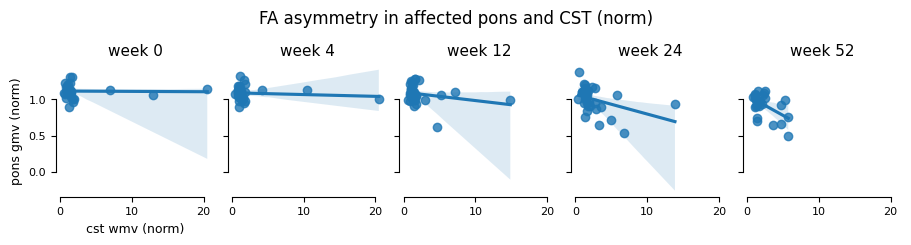

**Pearson R and p-value for FA asymmetry in affected CST and pons** 

week 0: r = -0.02148976324679735, p-value = 0.9118954978273517
week 4: r = -0.10081729851268477, p-value = 0.5829913288368838
week 12: r = -0.23475519848128942, p-value = 0.17463814758585533
week 24: r = -0.3924269093019123, p-value = 0.02389132732477102
week 52: r = -0.5293486998397485, p-value = 0.006507091527809273


In [23]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    cst_plot = cst[(cst.Week == week)]
    pons_plot = pons[(pons.Week == week)]
    cst_pons_plot = pd.merge(pons_plot, cst_plot, on = ['subj_id', 'Week'], suffixes = ('_pons', '_cst'))

    ax = axs[i]
    sns.regplot(x = 'right_norm_pons', y = 'right_norm_cst', data = cst_pons_plot, ax = ax)

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')
    

axs[0].set_ylabel("pons gmv (norm)")
axs[0].set_xlabel(f"cst wmv (norm)")
fig.suptitle(f"FA asymmetry in affected pons and CST (norm)", y = 1.15)

sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for FA asymmetry in affected CST and pons** \n")
for week in gl.weeks:
    cst_plot = cst[cst.Week == week]
    pons_plot = pons[(pons.Week == week)]
    cst_pons_plot = pd.merge(pons_plot, cst_plot, on = ['subj_id', 'Week'], suffixes = ('_pons', '_cst'))

    r_stat, p_stat = stats.pearsonr(cst_pons_plot['right_norm_pons'], cst_pons_plot['right_norm_cst'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')
